# Tahap 2 — Preprocessing & Augmentasi (Data Pipeline)

Langkah 1 tugas: *"Terapkan langkah prapemrosesan dasar seperti resizing, normalisasi, dan augmentasi
sederhana pada dataset."*

Seluruh pipeline ditulis di modul **`data_pipeline.py`**, bukan di notebook ini. Alasannya: Tahap 3
membandingkan 3+ arsitektur CNN, dan perbandingan itu hanya sahih kalau semuanya memakai preprocessing
yang **persis sama**. Kalau transform di-copy-paste ke tiap notebook training, perbedaan kecil yang tak
sengaja akan tercampur ke dalam hasil perbandingan. Notebook ini bertugas **mendemonstrasikan dan
memverifikasi** modul itu.

Dua temuan dari Tahap 1 yang harus ditangani di sini:

| Temuan Tahap 1 | Penanganan |
|---|---|
| 25 citra bermode RGBA/palette | `_to_rgb` di awal tiap transform |
| 666 citra (11%) < 224 px | resize + crop, dengan konsekuensi dicatat |
| Imbalance 1.73x | `class_weights()` atau `WeightedRandomSampler` |
| Pakai bobot pretrained | normalisasi statistik ImageNet, bukan statistik dataset |

## 1. Setup

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import data_pipeline as dp

dp.seed_everything(dp.SEED)
plt.rcParams["figure.dpi"] = 110

DEVICE = dp.get_device()
print(f"Device     : {DEVICE}")
print(f"Ukuran input: {dp.IMG_SIZE}x{dp.IMG_SIZE} (resize {dp.RESIZE_SIZE} sebelum center crop)")
print(f"Normalisasi : ImageNet mean={dp.IMAGENET_MEAN} std={dp.IMAGENET_STD}")
print(f"Dataset ini : mean={dp.DATASET_MEAN} std={dp.DATASET_STD}")

Device     : mps
Ukuran input: 224x224 (resize 256 sebelum center crop)
Normalisasi : ImageNet mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
Dataset ini : mean=(0.6405, 0.5803, 0.4929) std=(0.281, 0.2935, 0.3267)


## 2. Keputusan Desain Pipeline

### Ukuran input 224×224
Semua arsitektur yang dibandingkan (AlexNet, VGG16, ResNet, MobileNetV2, EfficientNet-B0) memakai input
224×224 pada bobot ImageNet-nya. Memakai ukuran seragam membuat perbandingan **waktu training/inferensi**
antar arsitektur adil — kalau ukurannya beda, yang terukur adalah beda resolusi, bukan beda arsitektur.

### Normalisasi: statistik ImageNet, bukan statistik dataset sendiri
Dataset ini jauh lebih terang dari ImageNet (mean R 0.64 vs 0.49) karena banyak foto studio berlatar putih.
Godaannya memakai statistik sendiri, tapi bobot pretrained dilatih pada input yang dinormalisasi dengan
statistik ImageNet — mengganti statistik berarti menggeser distribusi input menjauh dari yang "dikenal"
bobot tersebut. Statistik dataset tetap disediakan di modul (`normalize="dataset"`) untuk skenario
training from scratch.

### Train vs eval transform
Transform evaluasi **deterministik** (resize → center crop). Augmentasi acak di val/test membuat skor
berubah tiap kali dijalankan, sehingga perbandingan antar arsitektur jadi bising.

### Augmentasi: sederhana dan sadar-domain
- `RandomResizedCrop(scale=0.7–1.0)` — objek rempah umumnya memenuhi frame; crop agresif memotong objek
- `RandomHorizontalFlip` — aman, rempah tidak punya orientasi kiri/kanan baku
- `RandomRotation(15°)` — rotasi besar menambah padding hitam di sudut
- `ColorJitter` konservatif (hue hanya ±0.03) — **warna adalah fitur pembeda utama** di sini
  (kunyit vs jahe, bawang merah vs bawang putih); jitter hue agresif justru menghapus informasi kelas

Tidak dipakai: `RandomVerticalFlip` (beberapa kelas seperti serai dan kayu manis punya orientasi natural).

In [2]:
train_tf = dp.build_transforms(train=True, augment="basic")
eval_tf = dp.build_transforms(train=False)

print("TRAIN transform:")
print(train_tf)
print("\nEVAL transform:")
print(eval_tf)

TRAIN transform:
Compose(
      Lambda(_to_rgb, types=['object'])
      RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.85, 1.18), interpolation=bilinear, antialias=True)
      RandomHorizontalFlip(p=0.5)
      RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
      ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.85, 1.15), hue=(-0.03, 0.03))
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
)

EVAL transform:
Compose(
      Lambda(_to_rgb, types=['object'])
      Resize(size=[256], interpolation=bilinear, antialias=True)
      CenterCrop(size=(224, 224))
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
)


## 3. Efek Resize pada Citra Kecil
Tahap 1 menemukan 11% citra lebih kecil dari 224 px. Resize ke 224 berarti **upsampling** — detail yang
muncul adalah hasil interpolasi, bukan informasi asli. Perlu dilihat seberapa parah kerusakannya.

In [3]:
from PIL import Image
import pandas as pd

manifest = pd.read_csv(dp.SPLIT_DIR / "manifest.csv")
manifest["abspath"] = manifest["filepath"].map(lambda p: dp.PROJECT_DIR / p)

sizes = []
for p in manifest["abspath"]:
    with Image.open(p) as im:
        sizes.append(im.size)
manifest["width"] = [s[0] for s in sizes]
manifest["height"] = [s[1] for s in sizes]
manifest["min_side"] = manifest[["width", "height"]].min(axis=1)

small = manifest[manifest["min_side"] < dp.IMG_SIZE]
print(f"Citra dengan sisi terpendek < {dp.IMG_SIZE}: {len(small)} ({len(small)/len(manifest):.1%})")
print(f"  di train: {(small['split'] == 'train').sum()}")
print(f"  di val  : {(small['split'] == 'val').sum()}")
print(f"  di test : {(small['split'] == 'test').sum()}")
print(f"\nSisi terpendek — persentil:")
print(manifest["min_side"].describe(percentiles=[0.05, 0.1, 0.25, 0.5]).to_string())

Citra dengan sisi terpendek < 224: 666 (11.0%)
  di train: 486
  di val  : 87
  di test : 93

Sisi terpendek — persentil:
count    6031.00000
mean      537.44006
std       409.94539
min        59.00000
5%        183.00000
10%       210.00000
25%       400.00000
50%       500.00000
max      4000.00000


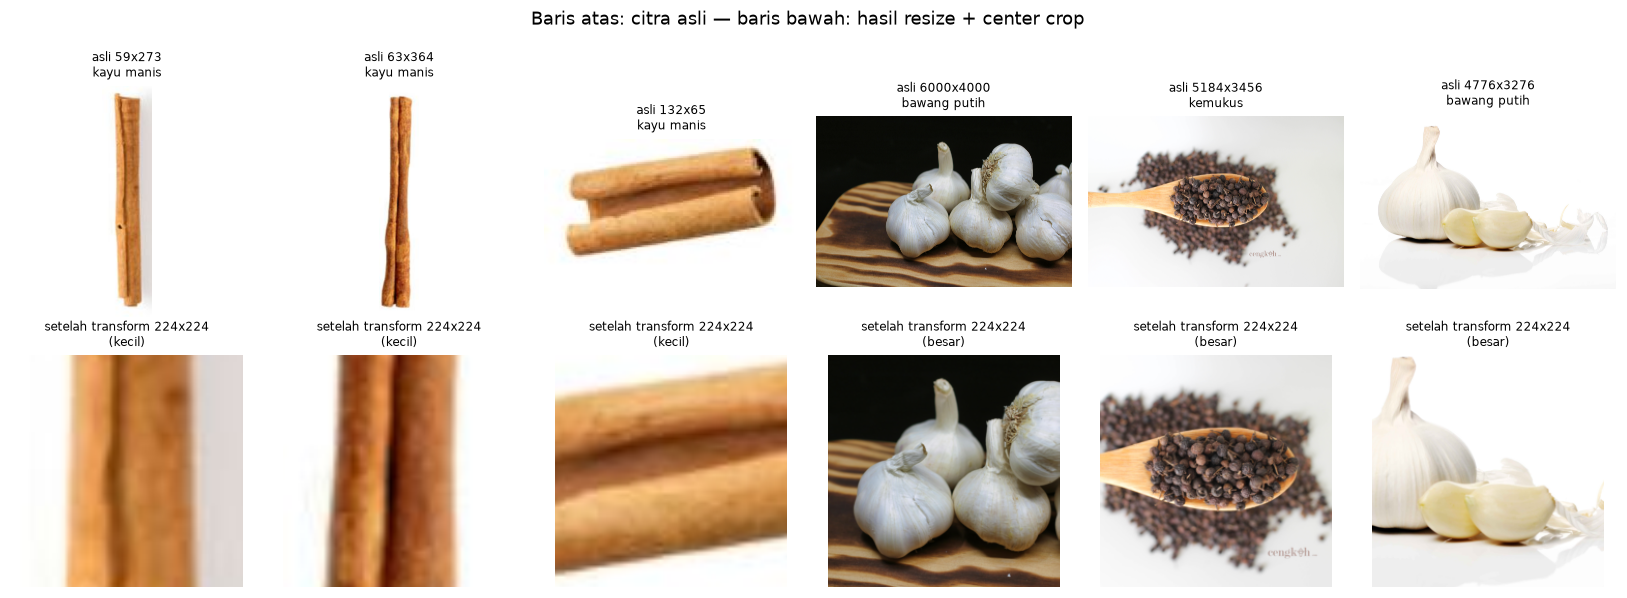

In [4]:
# Bandingkan hasil eval-transform pada citra kecil vs citra besar
rng = np.random.default_rng(dp.SEED)
contoh = pd.concat([
    small.nsmallest(3, "min_side").assign(kasus="kecil"),
    manifest.nlargest(3, "min_side").assign(kasus="besar"),
])

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for col, row in enumerate(contoh.itertuples(index=False)):
    img = Image.open(row.abspath).convert("RGB")
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"asli {row.width}x{row.height}\n{row.label}", fontsize=8)
    out = dp.denormalize(eval_tf(img))
    axes[1, col].imshow(out.permute(1, 2, 0).numpy())
    axes[1, col].set_title(f"setelah transform 224x224\n({row.kasus})", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Baris atas: citra asli — baris bawah: hasil resize + center crop")
plt.tight_layout()
plt.show()

## 4. Visualisasi Augmentasi
Augmentasi yang tidak pernah dilihat matanya gampang jadi bug diam-diam: crop terlalu agresif atau jitter
warna berlebihan akan menghapus informasi kelas, dan gejalanya hanya muncul sebagai akurasi yang mentok
tanpa sebab jelas.

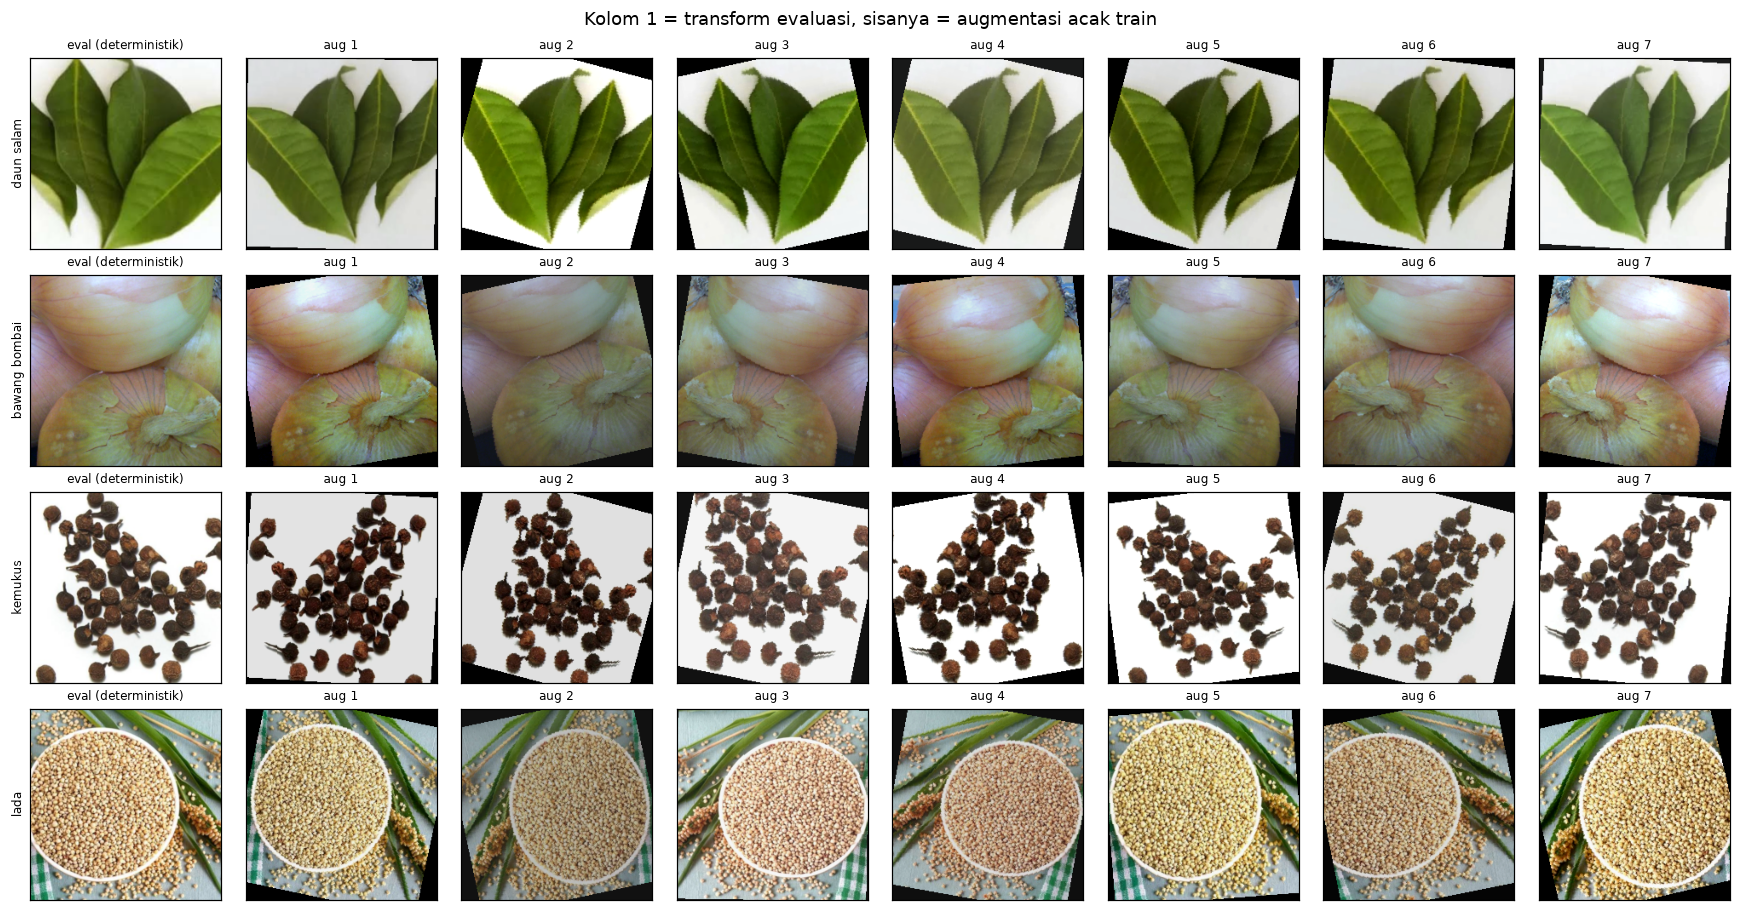

In [5]:
raw_ds = dp.build_datasets(augment="none")["train"]
sample_paths = [raw_ds.samples[i][0] for i in rng.choice(len(raw_ds.samples), 4, replace=False)]

N_AUG = 7
fig, axes = plt.subplots(len(sample_paths), N_AUG + 1, figsize=(2 * (N_AUG + 1), 2.1 * len(sample_paths)))
for r, path in enumerate(sample_paths):
    img = Image.open(path).convert("RGB")
    axes[r, 0].imshow(dp.denormalize(eval_tf(img)).permute(1, 2, 0).numpy())
    axes[r, 0].set_ylabel(Path(path).parent.name, fontsize=8)
    axes[r, 0].set_title("eval (deterministik)", fontsize=8)
    for c in range(1, N_AUG + 1):
        axes[r, c].imshow(dp.denormalize(train_tf(img)).permute(1, 2, 0).numpy())
        axes[r, c].set_title(f"aug {c}", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Kolom 1 = transform evaluasi, sisanya = augmentasi acak train")
plt.tight_layout()
plt.show()

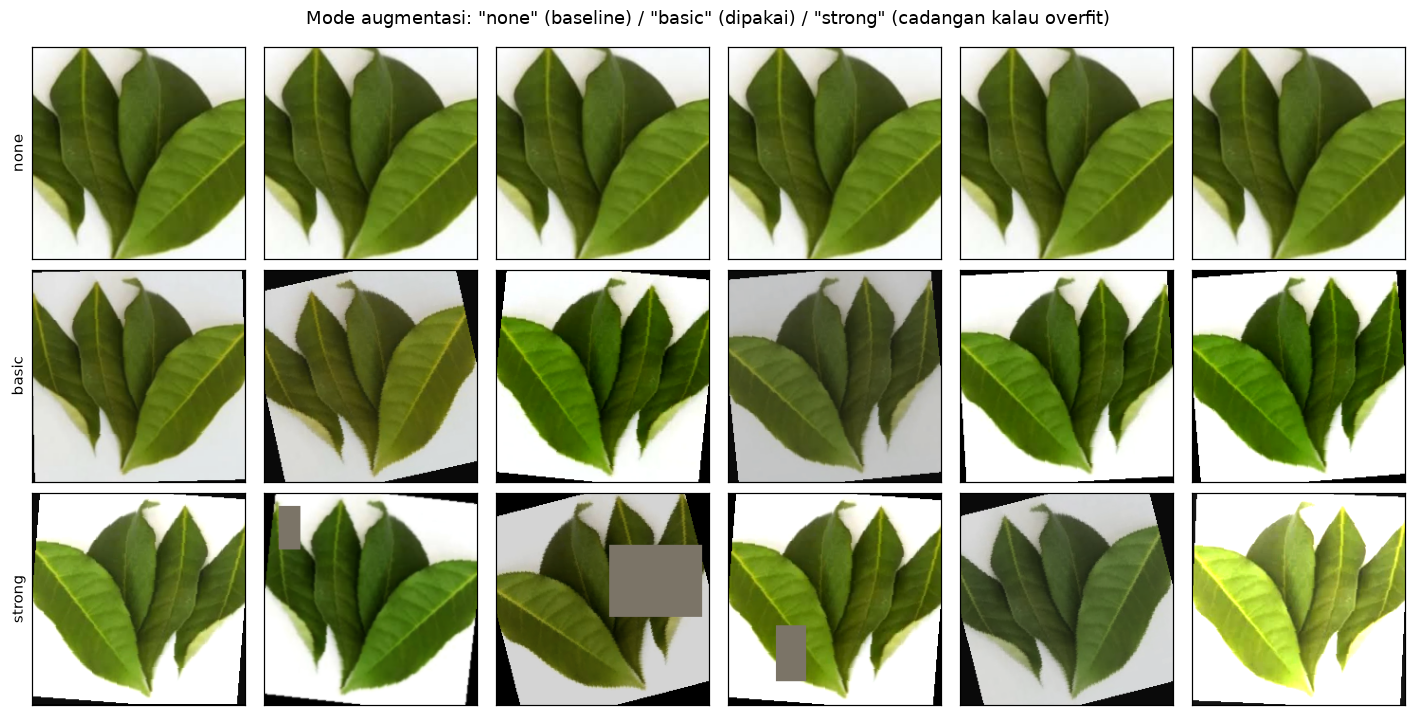

In [6]:
# Perbandingan tiga mode augmentasi pada satu citra yang sama
img = Image.open(sample_paths[0]).convert("RGB")
modes = ["none", "basic", "strong"]

fig, axes = plt.subplots(len(modes), 6, figsize=(13, 2.2 * len(modes)))
for r, mode in enumerate(modes):
    tf = dp.build_transforms(train=True, augment=mode)
    for c in range(6):
        axes[r, c].imshow(dp.denormalize(tf(img)).permute(1, 2, 0).numpy())
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(mode, fontsize=10)
fig.suptitle('Mode augmentasi: "none" (baseline) / "basic" (dipakai) / "strong" (cadangan kalau overfit)')
plt.tight_layout()
plt.show()

## 5. DataLoader & Penanganan Class Imbalance
Imbalance 1.73x tergolong ringan, jadi dua opsi tersedia dan **dipilih salah satu, bukan keduanya**
(menggabungkan sampler seimbang dengan loss berbobot akan mengoreksi berlebihan):

1. `class_weights()` → dipakai di `nn.CrossEntropyLoss(weight=...)` — default yang dipakai
2. `balanced=True` → `WeightedRandomSampler`, tiap batch seimbang kelas

In [7]:
BATCH_SIZE = 32
NUM_WORKERS = 4

loaders, ds = dp.build_dataloaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, augment="basic")

for split in dp.SPLITS:
    print(f"{split:5s}: {len(ds[split]):5d} citra, {len(loaders[split]):3d} batch")

print(f"\nJumlah kelas: {len(ds['train'].classes)}")

counts = dp.class_counts(ds["train"])
weights = dp.class_weights(ds["train"])
bobot = pd.DataFrame({
    "kelas": ds["train"].classes,
    "n_train": counts,
    "bobot": np.round(weights.numpy(), 4),
}).sort_values("n_train")
print("\nBobot kelas (5 tersedikit & 5 terbanyak):")
print(pd.concat([bobot.head(5), bobot.tail(5)]).to_string(index=False))
print(f"\nRentang bobot: {weights.min():.3f} - {weights.max():.3f} (rata-rata {weights.mean():.3f})")

train:  4221 citra, 131 batch
val  :   905 citra,  29 batch
test :   905 citra,  29 batch

Jumlah kelas: 31

Bobot kelas (5 tersedikit & 5 terbanyak):
        kelas  n_train  bobot
    asam jawa       85 1.5843
  kayu secang      109 1.2354
       jinten      120 1.1222
      cengkeh      128 1.0521
    andaliman      132 1.0202
         pala      144 0.9352
       kemiri      146 0.9224
   kayu manis      146 0.9224
 bukan rempah      146 0.9224
bawang bombai      146 0.9224

Rentang bobot: 0.922 - 1.584 (rata-rata 1.000)


/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


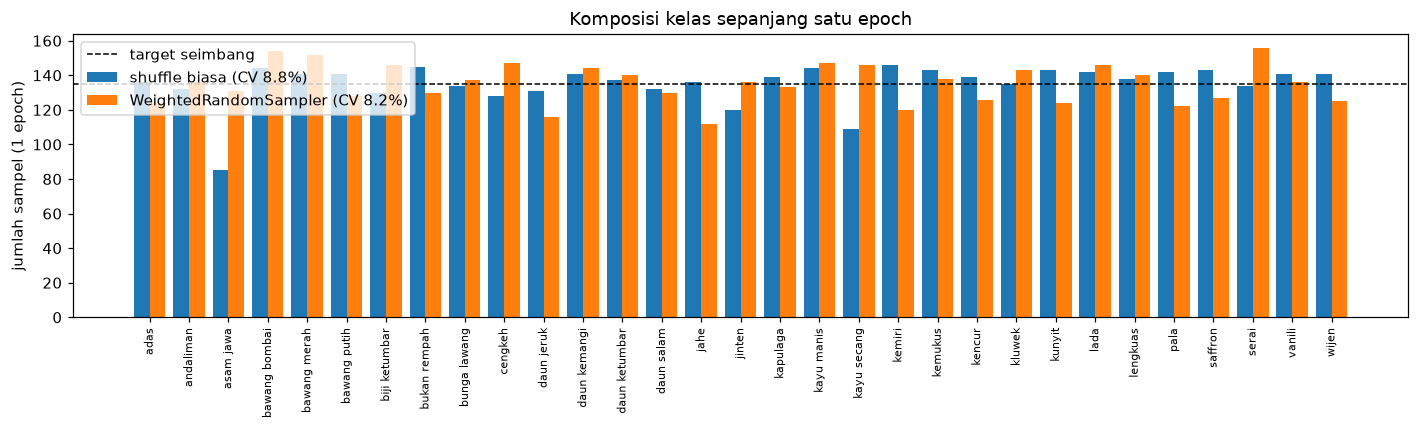

CV shuffle biasa     : 8.8%  (mencerminkan imbalance asli dataset)
CV sampler seimbang  : 8.2%
CV noise multinomial : 8.5%  (batas bawah teoretis untuk sampling with replacement)

Rentang shuffle : 85 - 146
Rentang sampler : 112 - 156

Sampler menurunkan ketimpangan: True


In [8]:
# Bukti bahwa WeightedRandomSampler benar-benar menyeimbangkan komposisi batch.
#
# Pengukuran harus memakai SATU EPOCH PENUH. Dengan hanya beberapa puluh batch,
# noise sampling-with-replacement (std ~ sqrt(n_per_kelas)) lebih besar daripada
# efek imbalance yang mau diukur, sehingga hasilnya menyesatkan.
bal_loaders, _ = dp.build_dataloaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, balanced=True)
n_kelas = len(ds["train"].classes)


def komposisi(loader):
    """Hitung sebaran kelas sepanjang satu epoch penuh."""
    hist = np.zeros(n_kelas, dtype=int)
    for _, y in loader:
        hist += np.bincount(y.numpy(), minlength=n_kelas)
    return hist


def cv(hist):
    """Coefficient of variation: std relatif terhadap mean, bebas dari skala."""
    return hist.std() / hist.mean()


h_shuffle = komposisi(loaders["train"])
h_balanced = komposisi(bal_loaders["train"])

# Noise dasar sampler seimbang: multinomial, bukan kesalahan pipeline
expected = h_balanced.sum() / n_kelas
noise_cv = np.sqrt(expected * (1 - 1 / n_kelas)) / expected

fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(n_kelas)
ax.bar(x - 0.2, h_shuffle, width=0.4, label=f"shuffle biasa (CV {cv(h_shuffle):.1%})")
ax.bar(x + 0.2, h_balanced, width=0.4, label=f"WeightedRandomSampler (CV {cv(h_balanced):.1%})")
ax.axhline(expected, ls="--", lw=1, color="black", label="target seimbang")
ax.set_xticks(x)
ax.set_xticklabels(ds["train"].classes, rotation=90, fontsize=7)
ax.set_ylabel("jumlah sampel (1 epoch)")
ax.set_title("Komposisi kelas sepanjang satu epoch")
ax.legend()
plt.tight_layout()
plt.show()

print(f"CV shuffle biasa     : {cv(h_shuffle):.1%}  (mencerminkan imbalance asli dataset)")
print(f"CV sampler seimbang  : {cv(h_balanced):.1%}")
print(f"CV noise multinomial : {noise_cv:.1%}  (batas bawah teoretis untuk sampling with replacement)")
print(f"\nRentang shuffle : {h_shuffle.min()} - {h_shuffle.max()}")
print(f"Rentang sampler : {h_balanced.min()} - {h_balanced.max()}")

sampler_ok = cv(h_balanced) < cv(h_shuffle)
print(f"\nSampler menurunkan ketimpangan: {sampler_ok}")

## 6. Verifikasi Pipeline

In [9]:
x, y = next(iter(loaders["train"]))

print(f"Shape batch : {tuple(x.shape)}")
print(f"dtype       : {x.dtype}")
print(f"Label       : {tuple(y.shape)} {y.dtype}, rentang [{y.min()}, {y.max()}]")
print(f"Rentang nilai: [{x.min():.3f}, {x.max():.3f}]")
print(f"NaN/Inf     : {bool(torch.isnan(x).any() or torch.isinf(x).any())}")

# Setelah normalisasi ImageNet, mean per kanal TIDAK harus 0 -- dataset ini lebih
# terang dari ImageNet, jadi nilai positif memang yang diharapkan.
print(f"\nMean per kanal setelah normalisasi: {x.mean(dim=(0, 2, 3)).numpy().round(3)}")
print(f"Std  per kanal setelah normalisasi: {x.std(dim=(0, 2, 3)).numpy().round(3)}")

xe, _ = next(iter(loaders["val"]))
print(f"\nVal batch (eval transform): mean {xe.mean(dim=(0, 2, 3)).numpy().round(3)}, "
      f"std {xe.std(dim=(0, 2, 3)).numpy().round(3)}")

Shape batch : (32, 3, 224, 224)
dtype       : torch.float32
Label       : (32,) torch.int64, rentang [0, 30]
Rentang nilai: [-2.118, 2.640]
NaN/Inf     : False

Mean per kanal setelah normalisasi: [0.353 0.235 0.062]
Std  per kanal setelah normalisasi: [1.299 1.342 1.344]



Val batch (eval transform): mean [0.37  0.248 0.008], std [1.184 1.278 1.357]


In [10]:
# Determinisme: transform eval harus identik tiap kali, transform train harus bervariasi
img = Image.open(sample_paths[0]).convert("RGB")

a, b = eval_tf(img), eval_tf(img)
print(f"Eval transform deterministik : {torch.equal(a, b)}")

dp.seed_everything(dp.SEED)
t1 = train_tf(img)
t2 = train_tf(img)
print(f"Train transform bervariasi   : {not torch.equal(t1, t2)}")

dp.seed_everything(dp.SEED)
t1b = train_tf(img)
print(f"Train transform reprodusibel : {torch.equal(t1, t1b)}")

# Seluruh dataset harus menghasilkan tensor 3 kanal, termasuk 25 citra RGBA/palette
non_rgb_paths = []
for p in manifest["abspath"]:
    with Image.open(p) as im:
        if im.mode != "RGB":
            non_rgb_paths.append(p)
print(f"\nCitra non-RGB di dataset: {len(non_rgb_paths)}")
shapes = {tuple(eval_tf(Image.open(p)).shape) for p in non_rgb_paths}
print(f"Shape hasil transform-nya: {shapes}")
assert shapes == {(3, dp.IMG_SIZE, dp.IMG_SIZE)}, "Masih ada tensor dengan jumlah kanal salah"
print("Semua citra non-RGB berhasil diseragamkan jadi 3 kanal.")

Eval transform deterministik : True


Train transform bervariasi   : True
Train transform reprodusibel : True



Citra non-RGB di dataset: 25


/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Shape hasil transform-nya: {(3, 224, 224)}
Semua citra non-RGB berhasil diseragamkan jadi 3 kanal.


In [11]:
# Throughput: kalau data loading jadi bottleneck, perbandingan waktu training
# antar arsitektur mengukur I/O, bukan arsitekturnya.
def benchmark(num_workers, n_batch=40, batch_size=BATCH_SIZE, repeat=3):
    """Median dari beberapa run; satu run tunggal terlalu bising untuk dipercaya."""
    hasil = []
    for _ in range(repeat):
        ld, _ = dp.build_dataloaders(batch_size=batch_size, num_workers=num_workers)
        it = iter(ld["train"])
        next(it)                      # buang batch pertama (biaya start worker)
        t0 = time.perf_counter()
        n = 0
        for _ in range(n_batch):
            xb, _ = next(it)
            n += xb.shape[0]
        hasil.append(n / (time.perf_counter() - t0))
        del it, ld
    return float(np.median(hasil)), float(np.std(hasil))


print(f"Throughput data loading (citra/detik, median dari 3 run, {os.cpu_count()} CPU):")
hasil = {}
for nw in (0, 2, 4, 8):
    med, sd = benchmark(nw)
    hasil[nw] = med
    print(f"  num_workers={nw}: {med:7.1f} img/s  (±{sd:.0f})")

best = max(hasil, key=hasil.get)
print(f"\nTercepat: num_workers={best} ({hasil[best]:.1f} img/s)")
print(f"Satu epoch train ({len(ds['train'])} citra) ~ {len(ds['train']) / hasil[best]:.1f} detik "
      f"hanya untuk data loading")

Throughput data loading (citra/detik, median dari 3 run, 8 CPU):


  num_workers=0:   246.5 img/s  (±13)


  num_workers=2:   386.2 img/s  (±11)


  num_workers=4:   699.9 img/s  (±20)


  num_workers=8:   549.0 img/s  (±17)

Tercepat: num_workers=4 (699.9 img/s)
Satu epoch train (4221 citra) ~ 6.0 detik hanya untuk data loading


In [12]:
# Uji di device sebenarnya: tensor harus bisa pindah ke MPS/CUDA dan dipakai model
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = torch.nn.Linear(model.fc.in_features, len(ds["train"].classes))
model = model.to(DEVICE).eval()

xb, yb = next(iter(loaders["val"]))
xb, yb = xb.to(DEVICE), yb.to(DEVICE)

# Panggilan pertama di MPS/CUDA memuat biaya kompilasi kernel (bisa ribuan ms).
# Tanpa warmup, angka ini akan dikira kecepatan inferensi sebenarnya.
with torch.no_grad():
    for _ in range(3):
        model(xb)
if DEVICE.type == "mps":
    torch.mps.synchronize()
elif DEVICE.type == "cuda":
    torch.cuda.synchronize()

waktu = []
with torch.no_grad():
    for _ in range(10):
        t0 = time.perf_counter()
        out = model(xb)
        if DEVICE.type == "mps":
            torch.mps.synchronize()
        elif DEVICE.type == "cuda":
            torch.cuda.synchronize()
        waktu.append(time.perf_counter() - t0)

dt = float(np.median(waktu))

print(f"Device        : {DEVICE}")
print(f"Input         : {tuple(xb.shape)}")
print(f"Output logits : {tuple(out.shape)} (harus [{BATCH_SIZE}, {len(ds['train'].classes)}])")
print(f"Forward pass  : {dt * 1000:.1f} ms / {xb.shape[0]} citra "
      f"= {xb.shape[0] / dt:.0f} img/s (median 10 run, setelah warmup)")
print(f"NaN di output : {bool(torch.isnan(out).any())}")

loss = torch.nn.CrossEntropyLoss(weight=weights.to(DEVICE))(out.float(), yb)
print(f"\nLoss (bobot kelas): {loss.item():.4f}  — acuan tebak acak ln({len(ds['train'].classes)}) = "
      f"{np.log(len(ds['train'].classes)):.4f}")
print("Loss awal di sekitar nilai acuan menandakan head klasifikasi memang belum terlatih.")

Device        : mps
Input         : (32, 3, 224, 224)
Output logits : (32, 31) (harus [32, 31])
Forward pass  : 77.1 ms / 32 citra = 415 img/s (median 10 run, setelah warmup)
NaN di output : False

Loss (bobot kelas): 3.3307  — acuan tebak acak ln(31) = 3.4340
Loss awal di sekitar nilai acuan menandakan head klasifikasi memang belum terlatih.


## 7. Ringkasan Tahap 2

In [13]:
checks = [
    ("Semua citra jadi 3 kanal RGB", shapes == {(3, dp.IMG_SIZE, dp.IMG_SIZE)}, f"{len(non_rgb_paths)} citra non-RGB ditangani"),
    ("Ukuran batch & shape benar", tuple(x.shape) == (BATCH_SIZE, 3, dp.IMG_SIZE, dp.IMG_SIZE), str(tuple(x.shape))),
    ("Tidak ada NaN/Inf", not bool(torch.isnan(x).any() or torch.isinf(x).any()), "bersih"),
    ("Transform eval deterministik", torch.equal(a, b), "identik antar pemanggilan"),
    ("Transform train bervariasi", not torch.equal(t1, t2), "augmentasi aktif"),
    ("Transform train reprodusibel", torch.equal(t1, t1b), f"seed={dp.SEED}"),
    ("Mapping kelas konsisten", ds["train"].class_to_idx == ds["test"].class_to_idx, f"{len(ds['train'].classes)} kelas"),
    ("Bobot kelas wajar (<2x)", float(weights.max() / weights.min()) < 2.0, f"{weights.max() / weights.min():.2f}x"),
    ("Sampler menyeimbangkan batch", sampler_ok, f"CV {cv(h_shuffle):.1%} -> {cv(h_balanced):.1%}"),
    ("Forward pass di device berhasil", not bool(torch.isnan(out).any()), f"{DEVICE}, {dt * 1000:.0f} ms/batch setelah warmup"),
]

report = pd.DataFrame(
    [{"pemeriksaan": n, "status": "PASS" if ok else "GAGAL", "detail": d} for n, ok, d in checks]
)
print(report.to_string(index=False))
n_fail = (report["status"] == "GAGAL").sum()
print(f"\n{len(report) - n_fail}/{len(report)} PASS")

print(f"""
Konfigurasi final yang dipakai Tahap 3:
  input          : {dp.IMG_SIZE}x{dp.IMG_SIZE}
  normalisasi    : ImageNet
  augmentasi     : basic (RandomResizedCrop + HFlip + Rotation 15 + ColorJitter)
  batch size     : {BATCH_SIZE}
  num_workers    : {best}
  imbalance      : class_weights pada CrossEntropyLoss
  train/val/test : {len(ds['train'])}/{len(ds['val'])}/{len(ds['test'])}
""")

                    pemeriksaan status                          detail
   Semua citra jadi 3 kanal RGB   PASS      25 citra non-RGB ditangani
     Ukuran batch & shape benar   PASS               (32, 3, 224, 224)
              Tidak ada NaN/Inf   PASS                          bersih
   Transform eval deterministik   PASS       identik antar pemanggilan
     Transform train bervariasi   PASS                augmentasi aktif
   Transform train reprodusibel   PASS                         seed=42
        Mapping kelas konsisten   PASS                        31 kelas
        Bobot kelas wajar (<2x)   PASS                           1.72x
   Sampler menyeimbangkan batch   PASS                 CV 8.8% -> 8.2%
Forward pass di device berhasil   PASS mps, 77 ms/batch setelah warmup



10/10 PASS

Konfigurasi final yang dipakai Tahap 3:
  input          : 224x224
  normalisasi    : ImageNet
  augmentasi     : basic (RandomResizedCrop + HFlip + Rotation 15 + ColorJitter)
  batch size     : 32
  num_workers    : 4
  imbalance      : class_weights pada CrossEntropyLoss
  train/val/test : 4221/905/905



### Tindak lanjut ke Tahap 3

Notebook training cukup memanggil:

```python
import data_pipeline as dp

dp.seed_everything(42)
loaders, ds = dp.build_dataloaders(batch_size=32, num_workers=4)
criterion = nn.CrossEntropyLoss(weight=dp.class_weights(ds["train"]).to(device))
```

Catatan untuk laporan:

- **11% citra ter-upsample** dari resolusi di bawah 224 px. Ini batas kualitas data, bukan bug —
  sebutkan di laporan sebagai faktor yang membatasi akurasi maksimum, terutama untuk `kayu manis`
  yang banyak citra sempit-tinggi.
- **Augmentasi `basic` dulu.** Naikkan ke `"strong"` hanya kalau terlihat gap besar antara akurasi
  train dan val (overfitting); menaikkannya sejak awal membuat sumber perbaikan sulit diatribusikan.
- **Pilih satu penanganan imbalance.** Default: `class_weights` pada loss. Jangan digabung dengan
  `balanced=True`.
- Semua arsitektur **wajib** memakai `build_dataloaders` yang sama agar perbandingannya sahih.